<a href="https://colab.research.google.com/github/afif-af/Natural-Language-Processing/blob/main/Build_a_Large_Language_Model_by_Sebastian_Raschka.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Chapter 02

In [ ]:
import urllib.request
url =("https://raw.githubusercontent.com/rasbt/"
      "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
      "the-verdict.txt")
file_path ="the-verdict.txt"
urllib.request.urlretrieve(url, file_path)

('the-verdict.txt', <http.client.HTTPMessage at 0x7b30cfa0c2c0>)

In [ ]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text =f.read()
print("Total number of character :", len(raw_text))
print(raw_text[:99])

Total number of character : 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [ ]:
import re
text ="Hello, World. This, is a test."
result =re.split(r'(\s)', text)
print(result)

['Hello,', ' ', 'World.', ' ', 'This,', ' ', 'is', ' ', 'a', ' ', 'test.']


In [ ]:
result =re.split(r'([,.]|\s)', text)
print(result)

['Hello', ',', '', ' ', 'World', '.', '', ' ', 'This', ',', '', ' ', 'is', ' ', 'a', ' ', 'test', '.', '']


In [ ]:
result =[item for item in result if item.strip()]
print(result)

['Hello', ',', 'World', '.', 'This', ',', 'is', 'a', 'test', '.']


In [ ]:
text ="Hello, world. Is this-- a test?"
result =re.split(r'([,.:;?_!"()\']|--|\s)', text)
result =[item.strip() for item in result if item.strip()]
print(result)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


In [ ]:
preprocessed =re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed =[item.strip() for item in preprocessed if item.strip()]
print(len(preprocessed))


4690


In [ ]:
print(preprocessed[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [ ]:
all_words =sorted(set(preprocessed))
vocab_size =len(all_words)
print(vocab_size)

1130


In [ ]:
vocab ={token: integer for integer, token in enumerate (all_words)}
for i, item in enumerate (vocab.items()):
  print(item)
  if i>=50:
    break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


In [ ]:
class SimpleTokenizerV1:
  def __init__(self, vocab):
    self.str_to_int =vocab
    self.int_to_str ={i:s for s, i in vocab.items()}

  def encode(self, text):
    preprocessed =re.split(r'([,.?_!"()\']|--|\s)', text)
    preprocessed =[
        item.strip() for item in preprocessed if item.strip()
    ]
    ids =[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text =" ".join([self.int_to_str[i] for i in ids])
    text =re.sub(r'\s+([,.?!"()\'])', r'\1', text)
    return text

In [ ]:
tokenizer =SimpleTokenizerV1(vocab)
text =""""It's the last he painted, you know,"
         Mrs. Gisburn said with pardonable pride."""
ids  =tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [ ]:
print(tokenizer.decode(ids))

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


In [ ]:
# text ="Hello, do you like tea?"
# print(tokenizer.encode(text))                    problem Hello was not use in The Verdict story


In [ ]:
all_tokens =sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])
vocab ={token:integer for integer, token in enumerate(all_tokens)}
print(len(vocab.items()))

1132


In [ ]:
for i, item in enumerate(list(vocab.items())[-5:]):
  print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|>', 1131)


In [ ]:
class SimpleTokenizerV2:
  def __init__(self, vocab):
    self.str_to_int =vocab
    self.int_to_str ={ i:s for s, i in vocab.items()}

  def encode(self, text):
    preprocessed =re.split(r'([,.:;?_!"()\']|--|\s)', text)
    preprocessed =[
        item.strip() for item in preprocessed if item.strip()
    ]
    preprocessed =[item if item in self.str_to_int
                        else "<|unk|>" for item in preprocessed]
    ids =[self.str_to_int[s] for s in preprocessed]
    return ids

  def decode(self, ids):
    text =" ".join([self.int_to_str[i] for i in ids])
    text =re.sub(r'\s+([,.?;:!"()\\])', r'\1', text)
    return text

In [ ]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."

In [ ]:
text  =" <|endoftext|> ".join((text1, text2))
print(text)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of the palace.


In [ ]:
tokenizer =SimpleTokenizerV2(vocab)
print(tokenizer.encode(text))

[1131, 5, 355, 1126, 628, 975, 10, 1130, 55, 988, 956, 984, 722, 988, 1131, 7]


In [ ]:
print(tokenizer.decode(tokenizer.encode(text)))

<|unk|>, do you like tea? <|endoftext|> In the sunlit terraces of the <|unk|>.


In [ ]:
from importlib.metadata import version
import tiktoken
print("tiktoken version:", version("tiktoken"))

tiktoken version: 0.13.0


In [ ]:
tokenizer =tiktoken.get_encoding("gpt2")


In [ ]:
text =(
    "Hello, do you like tea? <|endoftext|> In the sunlit terraces of someunknownPlace"

)
integers =tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114, 286, 617, 34680, 27271]


In [ ]:
strings =tokenizer.decode(integers)
print(strings)

Hello, do you like tea? <|endoftext|> In the sunlit terraces of someunknownPlace


In [ ]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text =f.read()

enc_text =tokenizer.encode(raw_text)
print(len(enc_text))


5145


In [ ]:
enc_sample =enc_text[50:]


In [ ]:
context_size =4
x =enc_sample[:context_size]
y =enc_sample[1:context_size+1]
print(f"x: {x}")
print(f"y:      {y}")

x: [290, 4920, 2241, 287]
y:      [4920, 2241, 287, 257]


In [ ]:
for i in range(1, context_size+1):
  context =enc_sample[:i]
  desired =enc_sample[i]
  print(context, "---->",desired)


[290] ----> 4920
[290, 4920] ----> 2241
[290, 4920, 2241] ----> 287
[290, 4920, 2241, 287] ----> 257


In [ ]:
for i in range(1, context_size +1):
  context =enc_sample[:i]
  desired =enc_sample[i]
  print(tokenizer.decode(context), "---->", tokenizer.decode([desired]))

 and ---->  established
 and established ---->  himself
 and established himself ---->  in
 and established himself in ---->  a


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader

In [ ]:
class GPTDatasetV1(Dataset):
  def __init__(self, txt, tokenzier, max_length, stride):
    self.input_ids =[]
    self.target_ids =[]

    token_ids =tokenizer.encode(txt)

    for i in range(0, len(token_ids) -max_length, stride):
      input_chunk  =token_ids[i:   i+max_length]
      target_chunk =token_ids[i+1: i+max_length +1]
      self.input_ids.append(torch.tensor(input_chunk))
      self.target_ids.append(torch.tensor(target_chunk))

  def __len__(self):
    return len(self.input_ids)

  def __getitem__(self, idx):
    return self.input_ids[idx], self.target_ids[idx]

In [ ]:
def create_dataloader_v1 (txt, batch_size=4, max_length=256,
                          stride=128, shuffle=True, drop_last=True,
                          num_workers=0):
  tokenizer =tiktoken.get_encoding("gpt2")
  dataset   =GPTDatasetV1(txt, tokenizer, max_length, stride)
  dataloader =DataLoader(
      dataset,
      batch_size  =batch_size,
      shuffle     =shuffle,
      drop_last   =drop_last,
      num_workers =num_workers

  )
  return dataloader



In [ ]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
  raw_text  = f.read()

dataloader  =create_dataloader_v1(
    raw_text, batch_size=1, max_length=4, stride=1, shuffle=False
)
data_iter   =iter(dataloader)
first_batch =next(data_iter)
print(first_batch)

[tensor([[  40,  367, 2885, 1464]]), tensor([[ 367, 2885, 1464, 1807]])]


In [ ]:
second_batch =next(data_iter)
print(second_batch)

[tensor([[ 367, 2885, 1464, 1807]]), tensor([[2885, 1464, 1807, 3619]])]


In [ ]:
dataloader =create_dataloader_v1(
    raw_text, batch_size=8, max_length =4,stride=4,
    shuffle=False
)

In [ ]:
data_iter =iter(dataloader)
inputs, targets =next(data_iter)
print("Inputs:\n",    inputs)
print("\nTargets:\n", targets)

Inputs:
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Targets:
 tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])


In [ ]:
input_ids =torch.tensor([2,3, 5,1])


In [ ]:
vocab_size=6
output_dim =3


In [ ]:
torch.manual_seed(123)
embedding_layer =torch.nn.Embedding(vocab_size, output_dim)
print(embedding_layer)

Embedding(6, 3)


In [ ]:
print(embedding_layer(torch.tensor([3])))


tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [ ]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


In [ ]:
vocab_size  =50257
output_dim =256
token_embedding_layer =torch.nn.Embedding(vocab_size, output_dim)

In [ ]:
max_length =4
dataloader =create_dataloader_v1(
    raw_text, batch_size=8, max_length=max_length, stride=max_length, shuffle=False,
)
data_iter =iter(dataloader)
inputs, targets =next(data_iter)
print("Token IDs: \n", inputs)
print("\nInputs shape: \n", inputs.shape)

Token IDs: 
 tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs shape: 
 torch.Size([8, 4])


In [ ]:
token_embeddings =token_embedding_layer(inputs)
print(token_embeddings.shape)

torch.Size([8, 4, 256])


In [ ]:
token_embeddings

tensor([[[ 0.4913,  1.1239,  1.4588,  ..., -0.3995, -1.8735, -0.1445],
         [ 0.4481,  0.2536, -0.2655,  ...,  0.4997, -1.1991, -1.1844],
         [-0.2507, -0.0546,  0.6687,  ...,  0.9618,  2.3737, -0.0528],
         [ 0.9457,  0.8657,  1.6191,  ..., -0.4544, -0.7460,  0.3483]],

        [[ 1.5460,  1.7368, -0.7848,  ..., -0.1004,  0.8584, -0.3421],
         [-1.8622, -0.1914, -0.3812,  ...,  1.1220, -0.3496,  0.6091],
         [ 1.9847, -0.6483, -0.1415,  ..., -0.3841, -0.9355,  1.4478],
         [ 0.9647,  1.2974, -1.6207,  ...,  1.1463,  1.5797,  0.3969]],

        [[-0.7713,  0.6572,  0.1663,  ..., -0.8044,  0.0542,  0.7426],
         [ 0.8046,  0.5047,  1.2922,  ...,  1.4648,  0.4097,  0.3205],
         [ 0.0795, -1.7636,  0.5750,  ...,  2.1823,  1.8231, -0.3635],
         [ 0.4267, -0.0647,  0.5686,  ..., -0.5209,  1.3065,  0.8473]],

        ...,

        [[-1.6156,  0.9610, -2.6437,  ..., -0.9645,  1.0888,  1.6383],
         [-0.3985, -0.9235, -1.3163,  ..., -1.1582, -1.13

In [ ]:
context_length =max_length
pos_embedding_layer =torch.nn.Embedding(context_length, output_dim)
pos_embeddings      =pos_embedding_layer(torch.arange(context_length))
print(pos_embeddings.shape)

torch.Size([4, 256])


In [ ]:
input_embeddings =token_embeddings +pos_embeddings
print(input_embeddings.shape)

torch.Size([8, 4, 256])


#Chapter 03

In [ ]:
import torch
inputs =torch.tensor(
     [[0.43, 0.15, 0.89], # Your (x^1)
      [0.55, 0.87, 0.66], # journey (x^2)
      [0.57, 0.85, 0.64], # starts (x^3)
      [0.22, 0.58, 0.33], # with (x^4)
      [0.77, 0.25, 0.10], # one (x^5)
      [0.05, 0.80, 0.55]] # step (x^6)
)

In [ ]:
inputs.shape

torch.Size([6, 3])

In [ ]:
query         =inputs[1]
attn_scores_2 =torch.empty(inputs.shape[0])
for i, x_i in enumerate(inputs):
  attn_scores_2[i] =torch.dot(x_i, query)
print(attn_scores_2)

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


In [ ]:
attn_weights_2_tmp =attn_scores_2 / attn_scores_2.sum()
print("Attention weights:", attn_weights_2_tmp)
print("Sum:", attn_weights_2_tmp.sum())

Attention weights: tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])
Sum: tensor(1.0000)


In [ ]:
def softmax_naive(x):
  return torch.exp(x) /torch.exp(x).sum(dim=0)

attn_weight_2_naive =softmax_naive(attn_scores_2)
print("Attention weights:", attn_weight_2_naive)
print("Sum:", attn_weight_2_naive.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [ ]:
attn_weights_2 =torch.softmax(attn_scores_2, dim=0)
print("Attention weights:", attn_weights_2)
print("Sum:", attn_weights_2.sum())

Attention weights: tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum: tensor(1.)


In [ ]:
query            =inputs[1]
context_vec_2    =torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
  context_vec_2 +=attn_weights_2[i] * x_i
print(context_vec_2)

tensor([0.4419, 0.6515, 0.5683])


In [ ]:
attn_scores =torch.empty(6,6)
for i, x_i in enumerate(inputs):
  for j, x_j in enumerate(inputs):
    attn_scores[i, j] =torch.dot(x_i,x_j)
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [ ]:
attn_scores=inputs @ inputs.T
print(attn_scores)

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [ ]:
attn_weights =torch.softmax(attn_scores, dim =-1)
print(attn_weights)

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


In [ ]:
row_2_sum =sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum:", row_2_sum)
print("All row sums: ", attn_weights.sum(dim=-1))

Row 2 sum: 1.0
All row sums:  tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


In [ ]:
all_context_vecs =attn_weights @inputs
print(all_context_vecs)

tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


In [ ]:
print("Previous 2nd context vector: ", context_vec_2)

Previous 2nd context vector:  tensor([0.4419, 0.6515, 0.5683])


In [ ]:
x_2 =inputs[1]
d_in =inputs.shape[1]
d_out=2


In [ ]:
torch.manual_seed(123)
W_query =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value =torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [ ]:
query_2 =x_2 @ W_query
key_2   =x_2 @ W_key
value_2 =x_2 @ W_value
print(value_2)

tensor([0.3951, 1.0037])


In [ ]:
keys   =inputs @ W_key
values =inputs @ W_value

print("Keys shape:", keys.shape)
print("values shape:", values.shape)

Keys shape: torch.Size([6, 2])
values shape: torch.Size([6, 2])


In [ ]:
keys_2        =keys[1]
attn_score_22 =query_2.dot(keys_2)
print(attn_score_22)

tensor(1.8524)


In [ ]:
attn_scores_2 =query_2 @keys.T
print(attn_scores_2)

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])


In [ ]:
d_k            =keys.shape[-1]
attn_weights_2 =torch.softmax(attn_scores_2 /d_k **0.55 , dim =-1)
print(attn_weights_2)

tensor([0.1508, 0.2244, 0.2181, 0.1323, 0.0927, 0.1817])


In [ ]:
context_vec_2 =attn_weights_2 @ values
print(context_vec_2)

tensor([0.3053, 0.8191])


In [ ]:
import torch.nn as nn
class SelfAttention_v1(nn.Module):
  def __init__(self, d_in, d_out):
    super().__init__()
    self.W_query  =nn.Parameter(torch.rand(d_in, d_out))
    self.W_key    =nn.Parameter(torch.rand(d_in, d_out))
    self.W_value  =nn.Parameter(torch.rand(d_in, d_out))

  def forward(self, x):
    keys    = x @ self.W_key
    queries = x @ self.W_query
    values  = x @ self.W_value
    attn_scores  = queries @ keys.T
    attn_weights = torch.softmax(
        attn_scores / (keys.shape [-1]**0.5), dim=-1
    )
    context_vec = attn_weights @ values
    return context_vec

In [ ]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
print(sa_v1(inputs))

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)


In [ ]:
class SelfAttention_v2(nn.Module):
  def __init__(self, d_in, d_out, qkv_bias=False):
    super().__init__()
    self.W_query =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_key   =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_value =nn.Linear(d_in, d_out, bias =qkv_bias)

  def forward(self, x):
    keys    =self.W_key(x)
    queries =self.W_query(x)
    values  =self.W_value(x)
    attn_scores =queries @ keys.T
    attn_weights =torch.softmax(
        attn_scores/(keys.shape[-1] **0.5 ), dim =-1
    )
    context_vec =attn_weights @ values
    return context_vec



In [ ]:
torch.manual_seed(789)
sa_v2 =SelfAttention_v2(d_in, d_out)
print(sa_v2(inputs))

tensor([[-0.0739,  0.0713],
        [-0.0748,  0.0703],
        [-0.0749,  0.0702],
        [-0.0760,  0.0685],
        [-0.0763,  0.0679],
        [-0.0754,  0.0693]], grad_fn=<MmBackward0>)


In [ ]:
queries =sa_v2.W_query(inputs)
keys    =sa_v2.W_key(inputs)
attn_scores =queries @ keys.T
attn_weights =torch.softmax(attn_scores / (keys.shape[-1] **0.5), dim=-1)
print(attn_weights)

tensor([[0.1921, 0.1646, 0.1652, 0.1550, 0.1721, 0.1510],
        [0.2041, 0.1659, 0.1662, 0.1496, 0.1665, 0.1477],
        [0.2036, 0.1659, 0.1662, 0.1498, 0.1664, 0.1480],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.1661, 0.1564],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.1585],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


In [ ]:
context_length  =attn_scores.shape[0]
mask_simple     =torch.tril(torch.ones(context_length, context_length))
print(mask_simple)


tensor([[1., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1.]])


In [ ]:
masked_simple =attn_weights *mask_simple
print(masked_simple)

tensor([[0.1921, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2041, 0.1659, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2036, 0.1659, 0.1662, 0.0000, 0.0000, 0.0000],
        [0.1869, 0.1667, 0.1668, 0.1571, 0.0000, 0.0000],
        [0.1830, 0.1669, 0.1670, 0.1588, 0.1658, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<MulBackward0>)


In [ ]:
row_sums           =masked_simple.sum(dim=-1, keepdim=True)
masked_simple_norm =masked_simple / row_sums
print(masked_simple_norm)



tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<DivBackward0>)


In [ ]:
mask = torch.triu(torch.ones(context_length, context_length), diagonal =1)
masked =attn_scores.masked_fill(mask.bool(), -torch.inf)
print(masked)

tensor([[0.2899,   -inf,   -inf,   -inf,   -inf,   -inf],
        [0.4656, 0.1723,   -inf,   -inf,   -inf,   -inf],
        [0.4594, 0.1703, 0.1731,   -inf,   -inf,   -inf],
        [0.2642, 0.1024, 0.1036, 0.0186,   -inf,   -inf],
        [0.2183, 0.0874, 0.0882, 0.0177, 0.0786,   -inf],
        [0.3408, 0.1270, 0.1290, 0.0198, 0.1290, 0.0078]],
       grad_fn=<MaskedFillBackward0>)


In [ ]:
attn_weights =torch.softmax(masked / (keys.shape[-1] **0.5), dim =1)
print(attn_weights)

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5517, 0.4483, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3800, 0.3097, 0.3103, 0.0000, 0.0000, 0.0000],
        [0.2758, 0.2460, 0.2462, 0.2319, 0.0000, 0.0000],
        [0.2175, 0.1983, 0.1984, 0.1888, 0.1971, 0.0000],
        [0.1935, 0.1663, 0.1666, 0.1542, 0.1666, 0.1529]],
       grad_fn=<SoftmaxBackward0>)


In [ ]:
torch.manual_seed(123)
dropout =torch.nn.Dropout(0.5)
example =torch.ones(6,6)
print(dropout(example))

tensor([[2., 2., 0., 2., 2., 0.],
        [0., 0., 0., 2., 0., 2.],
        [2., 2., 2., 2., 0., 2.],
        [0., 2., 2., 0., 0., 2.],
        [0., 2., 0., 2., 0., 2.],
        [0., 2., 2., 2., 2., 0.]])


In [ ]:
torch.manual_seed(123)
print(dropout(attn_weights))

tensor([[2.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.7599, 0.6194, 0.6206, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4921, 0.4925, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.3966, 0.0000, 0.3775, 0.0000, 0.0000],
        [0.0000, 0.3327, 0.3331, 0.3084, 0.3331, 0.0000]],
       grad_fn=<MulBackward0>)


In [ ]:
batch =torch.stack((inputs, inputs), dim=0)
print(batch.shape)

torch.Size([2, 6, 3])


In [ ]:
class CausalAttention(nn.Module):
  def __init__(self, d_in, d_out, context_length, dropout, qkv_bias =False):
    super().__init__()
    self.d_out =d_out
    self.W_query =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_key   =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_value =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.dropout =nn.Dropout(dropout)
    self.register_buffer(
        'mask',
        torch.triu(torch.ones(context_length, context_length),
                   diagonal=1)
    )

  def forward(self, x):
    b, num_tokens, d_in =x.shape
    keys =self.W_key(x)
    queries =self.W_query(x)
    values =self.W_value(x) # Corrected typo from 'vlaues'

    attn_scores =queries @ keys.transpose(1, 2)
    attn_scores.masked_fill(
        self.mask.bool()[:num_tokens, :num_tokens], -torch.inf
    )
    attn_weights =torch.softmax(
        attn_scores / (keys.shape[-1] **0.5) , dim =-1
    )
    attn_weights =self.dropout(attn_weights)
    context_vec =attn_weights @ values
    return context_vec

In [ ]:
torch.manual_seed(123)
context_length =batch.shape[1]
ca =CausalAttention(d_in, d_out, context_length, 0.0)
context_vecs =ca(batch)
print("Context_vecs.shape:", context_vecs.shape)


Context_vecs.shape: torch.Size([2, 6, 2])


In [ ]:
class MultiHeadAttentionWrapper(nn.Module):
  def __init__(self,d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
    super().__init__()
    self.heads =nn.ModuleList(
        [CausalAttention(
            d_in, d_out, context_length, dropout, qkv_bias
        )for _ in range(num_heads)]
    )

  def forward(self, x):
    return torch.cat([head(x) for head in self.heads], dim=-1)

In [ ]:
torch.manual_seed(123)
context_length =batch.shape[1]
d_in, d_out = 3, 2
mha =MultiHeadAttentionWrapper(
    d_in, d_out, context_length, 0.0, num_heads =2
)
context_vecs =mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape
      )

tensor([[[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]],

        [[-0.5337, -0.1051,  0.5085,  0.3508],
         [-0.5323, -0.1080,  0.5084,  0.3508],
         [-0.5323, -0.1079,  0.5084,  0.3506],
         [-0.5297, -0.1076,  0.5074,  0.3471],
         [-0.5311, -0.1066,  0.5076,  0.3446],
         [-0.5299, -0.1081,  0.5077,  0.3493]]], grad_fn=<CatBackward0>)
context_vecs.shape: torch.Size([2, 6, 4])


In [ ]:
class MultiHeadAttention(nn.Module):
  def __init__(self,d_in,d_out, context_length, dropout, num_heads, qkv_bias=False):
    super().__init__()
    assert (d_out % num_heads ==0), \
           "d_out must be divisible by num_heads"

    self.d_out =d_out
    self.num_heads =num_heads
    self.head_dim  =d_out// num_heads
    self.W_query   =nn.Linear(d_in, d_out, bias=qkv_bias)
    self.W_key     =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.W_values  =nn.Linear(d_in, d_out, bias =qkv_bias)
    self.out_proj  =nn.Linear(d_out, d_out)
    self.dropout   =nn.Dropout(dropout)
    self.register_buffer(
        "mask",
        torch.triu(torch.ones(context_length, context_length),
                   diagonal=1)
    )
  def forward(self, x):
    b, num_tokens, d_in =x.shape
    keys     =self.W_key(x)
    queries  =self.W_query(x)
    values   =self.W_values(x)

    keys      =keys.view(b, num_tokens, self.num_heads, self.head_dim)
    values    =values.view(b, num_tokens, self.num_heads, self.head_dim)
    queries   =queries.view(
        b, num_tokens, self.num_heads, self.head_dim
    )

    keys       =keys.transpose(1,2)
    queries    =queries.transpose(1,2)
    values     =values.transpose(1,2)

    attn_scores =queries @ keys.transpose(2,3)
    mask_bool   =self.mask.bool()[:num_tokens, :num_tokens]

    attn_scores.masked_fill_(mask_bool, -torch.inf)

    attn_weights =torch.softmax(
        attn_scores / (keys.shape[-1] **0.5), dim =-1
    )

    attn_weights =self.dropout(attn_weights)

    context_vec  =(attn_weights @ values).transpose(1,2)

    context_vec  =context_vec.contiguous().view(
        b, num_tokens, self.d_out
    )
    context_vec      =self.out_proj(context_vec)
    return context_vec

In [ ]:

a = torch.tensor([[[[0.2745, 0.6584, 0.2775, 0.8573],
                    [0.8993, 0.0390, 0.9268, 0.7388],
                    [0.7179, 0.7058, 0.9156, 0.4340]],

                    [[0.0772, 0.3565, 0.1479, 0.5331],
                    [0.4066, 0.2318, 0.4545, 0.9737],
                    [0.4606, 0.5159, 0.4220, 0.5786]]]])

In [ ]:
print(a @ a.transpose(2,3))

tensor([[[[1.3208, 1.1631, 1.2879],
          [1.1631, 2.2150, 1.8424],
          [1.2879, 1.8424, 2.0402]],

         [[0.4391, 0.7003, 0.5903],
          [0.7003, 1.3737, 1.0620],
          [0.5903, 1.0620, 0.9912]]]])


In [ ]:
first_head =a[0, 0, :, :]
first_res  =first_head @ first_head.T
print("First head: \n", first_res)

second_head =a[0, 1, :, :]
second_res =second_head @ second_head.T
print("Second head:\n", second_res)

First head: 
 tensor([[1.3208, 1.1631, 1.2879],
        [1.1631, 2.2150, 1.8424],
        [1.2879, 1.8424, 2.0402]])
Second head:
 tensor([[0.4391, 0.7003, 0.5903],
        [0.7003, 1.3737, 1.0620],
        [0.5903, 1.0620, 0.9912]])


In [ ]:
torch.manual_seed(123)
batch_size, context_length, d_in=batch.shape
d_out=2
mha=MultiHeadAttention(d_in, d_out, context_length, 0.0, num_heads=2)
context_vecs =mha(batch)
print(context_vecs)
print("context_vecs.shape:", context_vecs.shape)

tensor([[[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]],

        [[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2856, 0.3593],
         [0.2693, 0.3873],
         [0.2639, 0.3928],
         [0.2575, 0.4028]]], grad_fn=<ViewBackward0>)
context_vecs.shape: torch.Size([2, 6, 2])


#Chapter 04

In [ ]:
GPT_CONFIG_124M ={
    "vocab_size"    : 50257,
    "context_length": 1024,
    "emb_dim"       : 768,
    "n_heads"       : 12,
    "n_layers"      : 12,
    "drop_rate"     : 0.1,
    "qkv_bias"      : False
}

In [ ]:
import torch
import torch.nn as nn

class DummyGPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.tok_emb =nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_emb =nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.drop_emb=nn.Dropout(cfg["drop_rate"])
    self.trf_blocks=nn.Sequential(
        *[DummyTransformerBlock(cfg)
          for _ in range(cfg["n_layers"])]
    )
    self.final_norm =DummyLayerNorm(cfg["emb_dim"])
    self.out_head   =nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"], bias=False
    )

  def forward(self, in_idx):
    batch_size, seq_len =in_idx.shape
    tok_embeds          =self.tok_emb(in_idx)
    pos_embeds          =self.pos_emb(
        torch.arange(seq_len, device =in_idx.device)
    )
    x =tok_embeds + pos_embeds
    x =self.drop_emb(x)
    x =self.trf_blocks(x)
    x =self.final_norm(x)
    logits =self.out_head(x)
    return logits

In [ ]:
class DummyTransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()

  def forward(self, x):
    return x

class DummyLayerNorm(nn.Module):
  def __init__(self, normalized_shape, eps =1e-5):
    super().__init__()

  def forward(self, x):
    return x

In [ ]:
import tiktoken
tokenizer =tiktoken.get_encoding("gpt2")
batch=[]
txt1 ="Every effort moves you"
txt2 ="Every day hold a"

batch.append(torch.tensor(tokenizer.encode(txt1)))
batch.append(torch.tensor(tokenizer.encode(txt2)))
batch =torch.stack(batch, dim =0)
print(batch)

tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 1745,  257]])


In [ ]:
torch.manual_seed(123)
model =DummyGPTModel(GPT_CONFIG_124M)
logits =model(batch)
print("Output shape:", logits.shape)
print(logits)

Output shape: torch.Size([2, 4, 50257])
tensor([[[-1.2034,  0.3201, -0.7130,  ..., -1.5548, -0.2390, -0.4667],
         [-0.1192,  0.4539, -0.4432,  ...,  0.2392,  1.3469,  1.2430],
         [ 0.5307,  1.6720, -0.4695,  ...,  1.1966,  0.0111,  0.5835],
         [ 0.0139,  1.6755, -0.3388,  ...,  1.1586, -0.0435, -1.0400]],

        [[-1.0908,  0.1798, -0.9484,  ..., -1.6047,  0.2439, -0.4530],
         [-0.7860,  0.5581, -0.0610,  ...,  0.4835, -0.0077,  1.6621],
         [ 0.5525,  0.4192, -0.1347,  ...,  0.3754,  0.2626, -0.5079],
         [-0.2407, -0.7349, -0.5102,  ...,  2.0057, -0.3694,  0.1814]]],
       grad_fn=<UnsafeViewBackward0>)


In [ ]:
torch.manual_seed(123)
batch_example =torch.randn(2, 5)
layer         =nn.Sequential(nn.Linear(5, 6),
                             nn.ReLU())
out           =layer(batch_example)
print(out)


tensor([[0.2260, 0.3470, 0.0000, 0.2216, 0.0000, 0.0000],
        [0.2133, 0.2394, 0.0000, 0.5198, 0.3297, 0.0000]],
       grad_fn=<ReluBackward0>)


In [ ]:
mean =out.mean(dim =-1, keepdim =True)
var  =out.var(dim =-1, keepdim =True)
print("Mean:\n",mean)
print("Varience:\n", var)

Mean:
 tensor([[0.1324],
        [0.2170]], grad_fn=<MeanBackward1>)
Varience:
 tensor([[0.0231],
        [0.0398]], grad_fn=<VarBackward0>)


In [ ]:
out_norm =(out-mean)/torch.sqrt(var)
mean     =out_norm.mean(dim =-1, keepdim=True)
var      =out_norm.var(dim =-1, keepdim =True)
print("Normalized layer outputs:\n", out_norm)
print("Mean:\n", mean)
print("Variance:\n", var)


Normalized layer outputs:
 tensor([[ 0.6159,  1.4126, -0.8719,  0.5872, -0.8719, -0.8719],
        [-0.0189,  0.1121, -1.0876,  1.5173,  0.5647, -1.0876]],
       grad_fn=<DivBackward0>)
Mean:
 tensor([[9.9341e-09],
        [1.9868e-08]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [ ]:
torch.set_printoptions(sci_mode=False)
print("Mean:\n", mean)
print("Variance:\n", var)

Mean:
 tensor([[0.0000],
        [0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [ ]:
class LayerNorm(nn.Module):
  def __init__(self, emb_dim):
    super().__init__()
    self.eps   =1e-5
    self.scale =nn.Parameter(torch.ones(emb_dim))
    self.shift =nn.Parameter(torch.zeros(emb_dim))

  def forward(self, x):
    mean  =x.mean(dim =-1, keepdim=True)
    var   =x.var(dim =-1, keepdim=True, unbiased=False)
    norm_x=(x - mean) / torch.sqrt(var + self.eps)
    return self.scale * norm_x + self.shift



In [ ]:
ln     =LayerNorm(emb_dim =5)
out_ln =ln(batch_example)
mean   =out_ln.mean(dim=-1, keepdim=True)
var    =out_ln.var(dim=-1, unbiased=False, keepdim=True)
print("Mean:\n", mean)
print("Variance:\n", var)


Mean:
 tensor([[-0.0000],
        [ 0.0000]], grad_fn=<MeanBackward1>)
Variance:
 tensor([[1.0000],
        [1.0000]], grad_fn=<VarBackward0>)


In [ ]:
class GELU(nn.Module):
  def __init__(self):
    super().__init__()

  def forward(self, x):
    return 0.5 * x *(1 +torch.tanh( torch.sqrt(torch.tensor(2.0/torch.pi)) *
                                   (x +0.44715 * torch.pow(x, 3))))


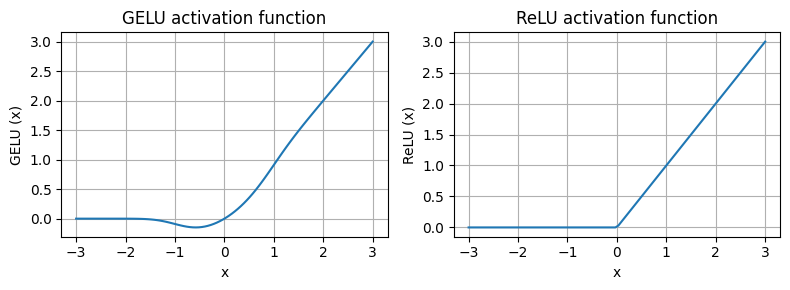

In [ ]:
import matplotlib.pyplot as plt
gelu, relu =GELU(), nn.ReLU()

x =torch.linspace(-3, 3, 100)
y_gelu, y_relu =gelu(x), relu(x)
plt.figure(figsize=(8,3))
for i, (y, label) in enumerate(zip([y_gelu, y_relu], ["GELU", "ReLU"]), 1):
  plt.subplot(1,2,i)
  plt.plot(x, y)
  plt.title(f"{label} activation function")
  plt.xlabel("x")
  plt.ylabel(f"{label} (x)")
  plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
class FeedForward(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.layers =nn.Sequential(
        nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
        GELU(),
        nn.Linear(4*cfg["emb_dim"], cfg["emb_dim"])
    )

  def forward(self, x):
    return self.layers(x)

In [ ]:
ffn =FeedForward(GPT_CONFIG_124M)
x   =torch.rand(2, 3, 768)
out =ffn(x)
print(out.shape)

torch.Size([2, 3, 768])


In [ ]:
class ExampleDeepNeuralNetwork(nn.Module):
  def __init__(self, layer_sizes, use_shortcut):
    super().__init__()
    self.use_shortcut =use_shortcut
    self.layers =nn.ModuleList([
        nn.Sequential (nn.Linear(layer_sizes[0], layer_sizes[1]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[1], layer_sizes[2]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[2], layer_sizes[3]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[3], layer_sizes[4]),
                       GELU()),
        nn.Sequential (nn.Linear(layer_sizes[4], layer_sizes[5]),
                       GELU()),

    ])

  def forward(self, x):
    for layer in self.layers:
      layer_output =layer(x)
      if self.use_shortcut and x.shape == layer_output.shape:
        x = x + layer_output
      else:
        x = layer_output

    return x

In [ ]:
layer_sizes  =[3,3,3,3,3,1]
sample_input =torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)
model_without_shorcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=False
)

In [ ]:
def print_gradients(model, x):
  output =model(x)
  target =torch.tensor([[0.]])

  loss_fn   =nn.MSELoss()
  loss   =loss_fn(output, target)

  loss.backward()

  for name, param in model.named_parameters():
    if 'weight' in name:
      if param.grad is not None:
        print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")
      else:
        print(f"{name} has no gradient.")

print_gradients(model_without_shorcut, sample_input)

layers.0.0.weight has gradient mean of 0.00020471324387472123
layers.1.0.weight has gradient mean of 0.0001231795467901975
layers.2.0.weight has gradient mean of 0.0007344745099544525
layers.3.0.weight has gradient mean of 0.0013871212722733617
layers.4.0.weight has gradient mean of 0.005026495084166527


In [ ]:
layer_sizes = [3,3,3,3,3,1]
sample_input = torch.tensor([[1., 0., -1.]])
torch.manual_seed(123)

model_with_shorcut = ExampleDeepNeuralNetwork(
    layer_sizes, use_shortcut=True
)

print_gradients (model_with_shorcut, sample_input)

layers.0.0.weight has gradient mean of 0.29920274019241333
layers.1.0.weight has gradient mean of 0.2749510407447815
layers.2.0.weight has gradient mean of 0.45466116070747375
layers.3.0.weight has gradient mean of 0.362958699464798
layers.4.0.weight has gradient mean of 1.763088583946228


In [ ]:
class TransformerBlock(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.att =MultiHeadAttention(
        d_in =cfg["emb_dim"],
        d_out=cfg["emb_dim"],
        context_length =cfg["context_length"],
        num_heads =cfg["n_heads"],
        dropout   =cfg["drop_rate"],
        qkv_bias  =cfg["qkv_bias"],

    )
    self.ff =FeedForward(cfg)
    self.norm1= LayerNorm(cfg["emb_dim"])
    self.norm2= LayerNorm(cfg["emb_dim"])
    self.drop_shortcut =nn.Dropout(cfg["drop_rate"])

  def forward(self, x):

    shortcut =x
    x  =self.norm1(x)
    x  =self.att(x)
    x  =self.drop_shortcut(x)
    x  =x +shortcut

    shortcut =x
    x  =self.norm2(x)
    x  =self.ff(x)
    x  =self.drop_shortcut(x)
    x  =x + shortcut

    return x

In [ ]:
torch.manual_seed(123)
x  =torch.rand(2, 4, 768)
block =TransformerBlock(GPT_CONFIG_124M)
output =block(x)

print("Input shape:", x.shape)
print("Ouput shape:", output.shape)


Input shape: torch.Size([2, 4, 768])
Ouput shape: torch.Size([2, 4, 768])


In [ ]:
class GPTModel(nn.Module):
  def __init__(self, cfg):
    super().__init__()
    self.tok_emb =nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
    self.pos_emb =nn.Embedding(cfg["context_length"], cfg["emb_dim"])
    self.drop_emb =nn.Dropout(cfg["drop_rate"])

    self.trf_blocks =nn.Sequential(
        *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])]
    )
    self.final_norm =LayerNorm(cfg["emb_dim"])
    self.out_head   =nn.Linear(
        cfg["emb_dim"], cfg["vocab_size"] , bias=False
    )

  def forward(self, in_idx):
    batch_size, seq_len =in_idx.shape
    tok_embeds =self.tok_emb(in_idx)

    pos_embeds  =self.pos_emb(
        torch.arange(seq_len, device =in_idx.device)
    )
    x = tok_embeds +pos_embeds
    x = self.drop_emb(x)
    x = self.trf_blocks(x)
    x = self.final_norm(x)
    logits =self.out_head(x)
    return logits

In [ ]:
torch.manual_seed(123)
model =GPTModel(GPT_CONFIG_124M)

out   =model(batch)
print("Input Batch:\n", batch)
print("\nOutput shape:", out.shape)
print(out)

Input Batch:
 tensor([[6109, 3626, 6100,  345],
        [6109, 1110, 1745,  257]])

Output shape: torch.Size([2, 4, 50257])
tensor([[[ 0.3428,  0.4351, -0.0825,  ...,  0.3370,  0.4601, -0.3005],
         [-0.2209, -0.5443, -0.9922,  ...,  0.0344,  0.5172, -0.3491],
         [ 0.7073,  0.0304,  0.0947,  ...,  0.0531, -0.3858, -0.2466],
         [-1.0247,  0.3700, -0.1148,  ...,  0.7367,  0.3972,  0.0401]],

        [[-0.2840,  0.1041,  0.0137,  ...,  0.2300,  0.4442, -0.7040],
         [ 0.1067,  0.3797, -0.2000,  ...,  0.7599,  0.2686,  0.1849],
         [ 1.3868, -0.0241, -0.5991,  ...,  0.0123, -0.1531, -0.1325],
         [-0.0749,  0.3530,  0.4195,  ...,  1.1688, -0.2881,  0.1083]]],
       grad_fn=<UnsafeViewBackward0>)


In [ ]:
total_params =sum(p.numel() for p in model.parameters())
print(f"Total number of parameters: {total_params:,}")

Total number of parameters: 163,009,536


In [ ]:
print("Token embedding layer shape: ", model.tok_emb.weight.shape)
print("Output layer shape:", model.out_head.weight.shape)

Token embedding layer shape:  torch.Size([50257, 768])
Output layer shape: torch.Size([50257, 768])


In [ ]:
total_params_gpt2 = (
    total_params - sum(p.numel()
    for p in model.out_head.parameters())
)
print(f"Number of trainable parameters"
      f"considering weight typing:{total_params_gpt2:,}")

Number of trainable parametersconsidering weight typing:124,412,160


In [ ]:
total_size_bytes =total_params * 4
total_size_mb    =total_size_bytes / (1024 *1024)
print(f"Total size of the model: {total_size_mb:.2f} MB")

Total size of the model: 621.83 MB


In [ ]:
def generate_text_simple(model, idx, max_new_tokens, context_size):
  for _ in range(max_new_tokens):
    idx_cond =idx[:, -context_size:]
    with torch.no_grad():
      logits =model(idx_cond)
    logits =logits[:, -1,:]
    probas =torch.softmax(logits, dim =-1)
    idx_next =torch.argmax(probas, dim =-1, keepdim=True)
    idx =torch.cat((idx, idx_next), dim =1)
  return idx


In [ ]:
start_context ="Hello, I am"
encoded =tokenizer.encode(start_context)
print("encoded:", encoded)

encoded_tensor =torch.tensor(encoded).unsqueeze(0)
print("encoded_tensor.shape:", encoded_tensor.shape)

encoded: [15496, 11, 314, 716]
encoded_tensor.shape: torch.Size([1, 4])


In [ ]:
model.eval()
out =generate_text_simple(
    model =model,
    idx =encoded_tensor,
    max_new_tokens =6,
    context_size =GPT_CONFIG_124M["context_length"]
)
print("Output:", out)
print("Output length:", len(out[0]))

Output: tensor([[15496,    11,   314,   716, 27018, 24086, 47843, 30961, 29739,   554]])
Output length: 10


In [ ]:
decoded_text =tokenizer.decode(out.squeeze(0).tolist())

In [ ]:
print(decoded_text)

Hello, I am Featureiman Byeswick Exit In


#Chapter 05

In [ ]:
import torch
GPT_CONFIG_124M ={
    "vocab_size": 50257,
    "context_length": 256,
    "emb_dim": 768,
    "n_heads": 12,
    "n_layers": 12,
    "drop_rate": 0.1,
    "qkv_bias": False
}

In [ ]:
torch.manual_seed(123)
model =GPTModel(GPT_CONFIG_124M)
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_values): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_feature

In [ ]:
import tiktoken

def text_to_token_ids (text, tokenizer):
  encoded        =tokenizer.encode(text, allowed_special={'<|endoftext|>'})
  encoded_tensor =torch.tensor(encoded).unsqueeze(0)
  return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
  flat =token_ids.squeeze(0)
  return tokenizer.decode(flat.tolist())

start_context ="Every effort moves you"
tokenizer     =tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model = model,
    idx   = text_to_token_ids(start_context, tokenizer),
    max_new_tokens =10,
    context_size   =GPT_CONFIG_124M["context_length"]
)


In [ ]:
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))


Output text:
 Every effort moves you rentingetic wasnم refres RexAngel infieldcigans


In [ ]:
inputs =torch.tensor([[16833, 3626 , 6100],
                      [40, 1107, 588]])


In [ ]:
targets =torch.tensor([[3626, 6100, 345],
                        [1107, 588, 11311]])

In [ ]:
with torch.no_grad():
  logits =model(inputs)
probas =torch.softmax(logits, dim=-1)
print(probas.shape)

torch.Size([2, 3, 50257])


In [ ]:
token_ids =torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


In [ ]:
print(f"Target batch 1:{token_ids_to_text(targets[0], tokenizer)}")
print(f"Output batch 1:{token_ids_to_text(token_ids[0].flatten(), tokenizer)}")


Target batch 1: effort moves you
Output batch 1: Armed heNetflix


In [ ]:
text_idx =0
target_probas_1 =probas[text_idx, [0,1,2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx =1
target_probas_2 =probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([0.0001, 0.0000, 0.0000])
Text 2: tensor([0.0000, 0.0001, 0.0000])


In [ ]:
log_probas =torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([ -9.5296, -10.3800, -11.3563, -11.4712,  -9.8154, -12.2528])


In [ ]:
avg_log_probas =torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.8009)


In [ ]:
neg_avg_log_probas =avg_log_probas * -1
print(neg_avg_log_probas)

tensor(10.8009)


In [ ]:
print("Logits shape:",logits.shape)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


In [ ]:
logits_flat =logits.flatten(0, 1)
targets_flat=targets.flatten()
print("Flatten logits", logits_flat.shape)
print("Flatten targets:", targets_flat.shape)


Flatten logits torch.Size([6, 50257])
Flatten targets: torch.Size([6])


In [ ]:
loss =torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.8009)


In [ ]:
file_path ="the-verdict.txt"
with open(file_path, "r", encoding="utf-8") as file:
  text_data =file.read()

In [ ]:
total_characters =len(text_data)
total_tokens =len(tokenizer.encode(text_data))
print("Character:", total_characters)
print("Token:", total_tokens)


Character: 20479
Token: 5145


In [ ]:
train_ratio =0.90
split_idx  =int(train_ratio * len(text_data))
train_data =text_data[:split_idx]
val_data   =text_data[split_idx:]

In [ ]:
torch.manual_seed(123)

train_loader =create_dataloader_v1(
    train_data,
    batch_size =2,
    max_length =GPT_CONFIG_124M["context_length"],
    stride     =GPT_CONFIG_124M["context_length"],
    drop_last  =True,
    shuffle    =True,
    num_workers=0
)

val_loader =create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length =GPT_CONFIG_124M["context_length"],
    stride     =GPT_CONFIG_124M["context_length"],
    drop_last  =False,
    shuffle    =False,
    num_workers=0
)

In [ ]:
print("Train loader:")
for x, y in train_loader:
  print(x.shape, y.shape)

print("\nValidation loader:")
for x, y  in val_loader:
  print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
  input_batch  =input_batch.to(device)
  target_batch =target_batch.to(device)
  logits  =model(input_batch)
  loss    =torch.nn.functional.cross_entropy(
      logits.flatten(0,1), target_batch.flatten()
  )
  return loss



In [ ]:
def calc_loss_loader(data_loader, model, device, num_batches=None):
  total_loss =0.
  if len(data_loader) ==0:
    return float("nan")
  elif num_batches is None:
    num_batches =len(data_loader)
  else:
    num_batches =min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      loss =calc_loss_batch(
          input_batch, target_batch, model, device
      )
      total_loss += loss.item()
    else:
      break
  return total_loss / num_batches



In [ ]:
device =torch.device ("cuda" if torch.cuda.is_available else "cpu")
model.to(device)
with torch.no_grad():
  train_loss =calc_loss_loader(train_loader, model, device)
  val_loss   =calc_loss_loader(val_loader, model, device)
print("Training loss:", train_loss)
print("Validation loss:", val_loss)


Training loss: 10.987016254001194
Validation loss: 10.980592727661133


In [ ]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs, eval_freq, eval_iter, start_context, tokenizer):
  train_losses, val_losses, track_tokens_seen =[], [], []
  tokens_seen, global_step =0, -1

  for epoch in range(num_epochs):
    model.train()
    for input_batch , target_batch in train_loader:
      optimizer.zero_grad()
      loss =calc_loss_batch(
          input_batch, target_batch, model, device
      )
      loss.backward()
      optimizer.step()
      tokens_seen +=input_batch.numel()
      global_step +=1

      if global_step % eval_freq == 0:
        train_loss, val_loss = evaluate_model(
            model, train_loader, val_loader, device, eval_iter
        )
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        track_tokens_seen.append(tokens_seen)
        print(f"Ep {epoch+1} (step {global_step: 06d}):"
              f"Train loss {train_loss:.3f},"
              f"val loss {val_loss:.3f}")
    generate_and_print_sample(
        model, tokenizer, device, start_context
    )
  return train_losses, val_losses, track_tokens_seen

In [ ]:
def evaluate_model (model, train_loader, val_loader, device, eval_iter):
  model.eval()
  with torch.no_grad():
    train_loss =calc_loss_loader(
        train_loader, model, device, num_batches =eval_iter
    )

    val_loss   =calc_loss_loader(
        val_loader, model, device, num_batches=eval_iter
    )
  model.train()
  return train_loss, val_loss

In [ ]:
def generate_and_print_sample(model, tokenizer, device, start_context):
  model.eval()
  context_size =model.pos_emb.weight.shape[0]
  encoded      =text_to_token_ids(start_context, tokenizer).to(device)
  with torch.no_grad():
    token_ids =generate_text_simple(
        model=model, idx =encoded,
        max_new_tokens =50, context_size =context_size
    )
  decoded_text =token_ids_to_text(token_ids, tokenizer)
  print(decoded_text.replace("\n", " "))
  model.train()

In [ ]:
torch.manual_seed(123)
model =GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer =torch.optim.AdamW(
    model.parameters(),
    lr=0.0004, weight_decay =0.1
)
num_epochs =10
train_losses, val_losses, tokens_seen =train_model_simple(
    model,train_loader, val_loader, optimizer, device,
    num_epochs =num_epochs, eval_freq=5, eval_iter=5,
    start_context ="Every effort moves you", tokenizer =tokenizer
)

Ep 1 (step  00000):Train loss 9.797,val loss 9.900
Ep 1 (step  00005):Train loss 8.071,val loss 8.333
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (step  00010):Train loss 6.632,val loss 7.052
Ep 2 (step  00015):Train loss 6.065,val loss 6.614
Every effort moves you,,,,,,,,,,,,,,.                                   
Ep 3 (step  00020):Train loss 5.685,val loss 6.493
Ep 3 (step  00025):Train loss 5.646,val loss 6.498
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and
Ep 4 (step  00030):Train loss 5.565,val loss 7.248
Ep 4 (step  00035):Train loss 5.164,val loss 6.457
Every effort moves you a                                                 
Ep 5 (step  00040):Train loss 4.338,val loss 6.316
Every effort moves you know         "I had been. I had been--and it--and it's had been.        "I had been to the picture it--and it's it's
Ep 6 (step  00045):Train loss 3.9

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
  fig, ax1 =plt.subplots(figsize =(5, 3))
  ax1.plot(epochs_seen, train_losses, label="Training loss")
  ax1.plot(epochs_seen, val_losses, linestyle="-.", label="validation loss")
  ax1.set_xlabel("Epochs")
  ax1.set_ylabel("Loss")
  ax1.legend(loc="upper right")
  ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
  ax2 =ax1.twiny()
  ax2.plot(tokens_seen, train_losses, alpha =0)
  ax2.set_xlabel("Tokens seen")
  fig.tight_layout()
  plt.show()

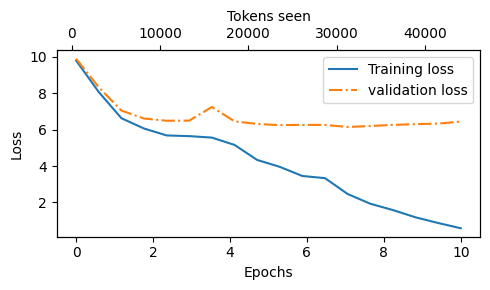

In [ ]:
epochs_tensor =torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [ ]:
model.to("cpu")
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_values): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_feature

In [ ]:
tokenizer=tiktoken.get_encoding("gpt2")
token_ids =generate_text_simple(
    model=model,
    idx  =text_to_token_ids("Every effort moves you ", tokenizer),
    max_new_tokens =25,
    context_size =GPT_CONFIG_124M["context_length"]
)
print("output text:\n", token_ids_to_text(token_ids, tokenizer))


output text:
 Every effort moves you  terrace.

I glanced after him, struck by his last word. Victor Grindle was, in fact, becoming


In [ ]:
vocab ={
    "closer": 0,
    "every": 1,
    "effort":2,
    "forward":3,
    "inches":4,
    "moves":5,
    "pizza":6,
    "toward":7,
    "you":8
}
inverse_vocab ={v:k for k, v in vocab.items()}

In [ ]:
next_token_logits =torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

In [ ]:
probas =torch.softmax(next_token_logits, dim=0)
next_token_id =torch.argmax(probas).item()
print(inverse_vocab[next_token_id])

forward


In [ ]:
torch.manual_seed(123)
next_token_id =torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


In [ ]:
def print_sampled_tokens(probas):
  torch.manual_seed(123)
  sample =[torch.multinomial(probas, num_samples =1).item()
           for i in range(1000)]
  sampled_ids =torch.bincount(torch.tensor(sample))
  for i, freq in enumerate(sampled_ids):
    print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


In [ ]:
def softmax_with_temperature(logits, temperature):
  scaled_logits =logits /temperature
  return torch.softmax(scaled_logits, dim=0)

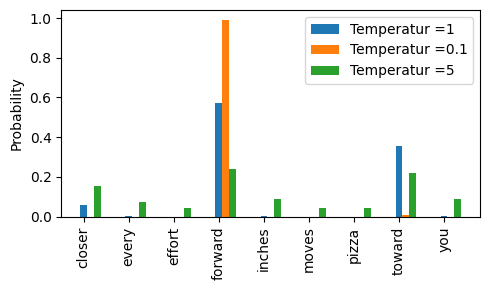

In [ ]:
temperatures =[1, 0.1, 5]
scaled_probas =[softmax_with_temperature(next_token_logits, T)for T in temperatures]
x =torch.arange(len(vocab))
bar_width =0.15
fig, ax =plt.subplots(figsize=(5,3))
for i, T in enumerate(temperatures):
  rects =ax.bar(x +i *bar_width, scaled_probas[i], bar_width, label=f'Temperatur ={T}')
ax.set_ylabel ('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation =90)
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
top_k=3
top_logits, top_pos =torch.topk(next_token_logits, top_k)
print("Top logits:", top_logits)
print("Top positions:", top_pos)


Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


In [ ]:
new_logits =torch.where(
    condition=next_token_logits <top_logits[-1],
    input =torch.tensor(float('-inf')),
    other =next_token_logits
)
print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


In [ ]:
topk_probas =torch.softmax(new_logits, dim =0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


In [ ]:
def generate(model, idx, max_new_tokens, context_size,
             temperature=0.0, top_k =None, eos_id=None):
  for _ in range(max_new_tokens):
    idx_cond =idx[:, -context_size:]
    with torch.no_grad():
      logits =model(idx_cond)
    logits =logits[:, -1, :]

    if top_k is not None:
      top_logits , _ =torch.topk(logits, top_k)
      min_val = top_logits[:, -1]
      logits =torch.where(
          logits <min_val,
          torch.tensor(float("-inf")).to(logits.device),
          logits # Added this argument to fix the TypeError
      )
    if temperature >0.0:
      logits =logits /temperature
      probs =torch.softmax(logits, dim=-1)
      idx_next =torch.multinomial(probs, num_samples =1)
    else:
      idx_next =torch.argmax(logits, dim=-1, keepdim=True)
    if idx_next ==eos_id:
      break
    idx =torch.cat((idx, idx_next), dim=1)
  return idx

In [ ]:
torch.manual_seed(123)
token_ids =generate(
    model =model,
    idx =text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens =15,
    context_size =GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

In [ ]:
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you?"
His up surprise. Th one his glory, so by his knees


In [ ]:
torch.save(model.state_dict(), "model.pth")

In [ ]:
model=GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", map_location=device))
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_values): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_feature

In [ ]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    },
    "model_and_optimizer.pth")

In [ ]:
checkpoint =torch.load("model_and_optimizer.pth", map_location=device)
model =GPTModel(GPT_CONFIG_124M)
model.load_state_dict (checkpoint["model_state_dict"])
optimizer =torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay =0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(256, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=False)
        (W_key): Linear(in_features=768, out_features=768, bias=False)
        (W_values): Linear(in_features=768, out_features=768, bias=False)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_feature

In [ ]:
import urllib.request
url = (
  "https://raw.githubusercontent.com/rasbt/"
  "LLMs-from-scratch/main/ch05/"
  "01_main-chapter-code/gpt_download.py"
)
filename =url.split("/") [-1]
urllib.request.urlretrieve(url, filename)

('gpt_download.py', <http.client.HTTPMessage at 0x7b2f8681a870>)

In [ ]:
from gpt_download import download_and_load_gpt2
settings, params =download_and_load_gpt2(
    model_size ="124M", models_dir="gpt2"
)

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


In [ ]:
print("settings:", settings)
print("parameter dictionary keys:", params.keys)


settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}
parameter dictionary keys: <built-in method keys of dict object at 0x7b2d431a3080>


In [ ]:
print("Token embedding weight tensor dimensions:", params["wte"].shape)

Token embedding weight tensor dimensions: (50257, 768)


In [ ]:
model_configs = {
"gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
"gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
"gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
"gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

In [ ]:
model_name ="gpt2-small (124M)"
NEW_CONFIG =GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])


In [ ]:
NEW_CONFIG.update({"context_length": 1024})

In [ ]:
NEW_CONFIG.update({"qkv_bias":True})


In [ ]:
gpt =GPTModel(NEW_CONFIG)
gpt.eval()

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_values): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=

In [ ]:
def assign(left,right):
  if left.shape !=right.shape:
    raise ValueError(f"shape mismatch. Left: {left.shape},"
                     f"Right: {right.shape}")
  return torch.nn.Parameter(torch.tensor(right))


In [ ]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    for b in range(len(params["blocks"])):
      q_w, k_w, v_w = np.split(
      (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
      gpt.trf_blocks[b].att.W_query.weight = assign(
      gpt.trf_blocks[b].att.W_query.weight, q_w.T)
      gpt.trf_blocks[b].att.W_key.weight = assign(
      gpt.trf_blocks[b].att.W_key.weight, k_w.T)
      gpt.trf_blocks[b].att.W_values.weight = assign(
      gpt.trf_blocks[b].att.W_values.weight, v_w.T)
      q_b, k_b, v_b = np.split(
      (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
      gpt.trf_blocks[b].att.W_query.bias = assign(
      gpt.trf_blocks[b].att.W_query.bias, q_b)
      gpt.trf_blocks[b].att.W_key.bias = assign(
      gpt.trf_blocks[b].att.W_key.bias, k_b)
      gpt.trf_blocks[b].att.W_values.bias = assign(
      gpt.trf_blocks[b].att.W_values.bias, v_b)
      gpt.trf_blocks[b].att.out_proj.weight = assign(
      gpt.trf_blocks[b].att.out_proj.weight,
      params["blocks"][b]["attn"]["c_proj"]["w"].T)
      gpt.trf_blocks[b].att.out_proj.bias = assign(
      gpt.trf_blocks[b].att.out_proj.bias,
      params["blocks"][b]["attn"]["c_proj"]["b"])
      gpt.trf_blocks[b].ff.layers[0].weight = assign(
      gpt.trf_blocks[b].ff.layers[0].weight,
      params["blocks"][b]["mlp"]["c_fc"]["w"].T)
      gpt.trf_blocks[b].ff.layers[0].bias = assign(
      gpt.trf_blocks[b].ff.layers[0].bias,
      params["blocks"][b]["mlp"]["c_fc"]["b"])
      gpt.trf_blocks[b].ff.layers[2].weight = assign(
      gpt.trf_blocks[b].ff.layers[2].weight,
      params["blocks"][b]["mlp"]["c_proj"]["w"].T)
      gpt.trf_blocks[b].ff.layers[2].bias = assign(
      gpt.trf_blocks[b].ff.layers[2].bias,
      params["blocks"][b]["mlp"]["c_proj"]["b"])
      gpt.trf_blocks[b].norm1.scale = assign(
      gpt.trf_blocks[b].norm1.scale,
      params["blocks"][b]["ln_1"]["g"])
      gpt.trf_blocks[b].norm1.shift = assign(
      gpt.trf_blocks[b].norm1.shift,
      params["blocks"][b]["ln_1"]["b"])
      gpt.trf_blocks[b].norm2.scale = assign(
      gpt.trf_blocks[b].norm2.scale,
      params["blocks"][b]["ln_2"]["g"])
      gpt.trf_blocks[b].norm2.shift = assign(
      gpt.trf_blocks[b].norm2.shift,
      params["blocks"][b]["ln_2"]["b"])
    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])

In [ ]:
load_weights_into_gpt(gpt, params)
gpt.to(device)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.1, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_values): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=

In [ ]:
torch.manual_seed(123)
token_ids =generate(
    model=gpt,
    idx =text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size =NEW_CONFIG["context_length"],
    top_k =50,
    temperature =1.5

)

In [ ]:
print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you as usual the campaign to raise awareness of the matter. It wouldn't have anything more right than "an effort by a line


#Chapter 06

In [ ]:
import urllib.request
import zipfile
import os
from pathlib import Path

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path= "sms_spam_collection.zip"
extracted_path ="sms_spam_collection"
data_file_path =Path(extracted_path) / "SMSSpamCollection.tsv"

def download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path):
  if data_file_path.exists():
    print(f"{data_file_path} already exists. Skipping download and extraction")
    return

  with urllib.request.urlopen(url) as response:
    with open(zip_path, "wb") as out_file:
      out_file.write(response.read())

  with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extracted_path)

  original_file_path =Path(extracted_path) / "SMSSpamCollection"
  os.rename(original_file_path, data_file_path)
  print(f"File download and saved as {data_file_path}")

download_and_unzip_spam_data(url, zip_path, extracted_path, data_file_path)



sms_spam_collection/SMSSpamCollection.tsv already exists. Skipping download and extraction


In [ ]:
import pandas as pd
df =pd.read_csv(
    data_file_path, sep="\t", header =None, names=["Label", "Text"]
)
df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [ ]:
print(df["Label"].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
def create_balanced_dataset(df):
  num_spam =df[df["Label"] =="spam"].shape[0]
  ham_subset =df[df["Label"] =="ham"].sample(
      num_spam, random_state=123
  )
  balanced_df =pd.concat([
      ham_subset, df[df["Label"] =="spam"]
  ])
  return balanced_df

balanced_df =create_balanced_dataset(df)
print(balanced_df["Label"].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


In [ ]:
balanced_df["Label"] =balanced_df["Label"].map({"ham":0, "spam":1})

In [ ]:
def random_split(df, train_frac, validation_frac):
  df =df.sample(
      frac =1, random_state=123
  ).reset_index(drop=True)
  train_end =int(len(df) * train_frac)
  validation_end =train_end + int(len(df) * validation_frac)

  train_df =df[:train_end]
  validation_df =df[train_end:validation_end]
  test_df =df[validation_end:]

  return train_df, validation_df, test_df

train_df, validation_df, test_df =random_split(
    balanced_df, 0.7, 0.1
)


In [ ]:
train_df.to_csv("train.csv", index=None)
validation_df.to_csv("validation.csv", index=None)
test_df.to_csv("test.csv", index=None)


In [ ]:
import tiktoken
tokenizer =tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))


[50256]


In [ ]:
import torch
from torch.utils.data import Dataset

class SpamDataset(Dataset):
  def __init__(self, csv_file, tokenizer, max_length=None, pad_token_id=50256):
    self.data =pd.read_csv(csv_file)

    self.encoded_texts =[
        tokenizer.encode(text) for text in self.data["Text"]
    ]

    if max_length is None:
      self.max_length =self._longest_encoded_length()
    else:
      self.max_length =max_length

      self.encoded_texts =[
          encoded_text[:self.max_length]
          for encoded_text in self.encoded_texts
      ]

    self.encoded_texts =[
        encoded_text + [pad_token_id] * (self.max_length -len(encoded_text))
        for encoded_text in self.encoded_texts
    ]

  def __getitem__(self, index):
    encoded =self.encoded_texts[index]
    label   =self.data.iloc[index]["Label"]
    return (
        torch.tensor(encoded, dtype =torch.long),
        torch.tensor(label, dtype=torch.long)
    )

  def __len__(self):
    return len(self.data)

  def _longest_encoded_length(self):
    max_length =0
    for encoded_text in self.encoded_texts:
      encoded_length =len(encoded_text)
      if encoded_length >max_length:
        max_length =encoded_length
    return max_length

In [ ]:
train_dataset =SpamDataset(
    csv_file ="train.csv",
    max_length =None,
    tokenizer =tokenizer
)

In [ ]:
print(train_dataset.max_length)

120


In [ ]:
val_dataset =SpamDataset(
    csv_file ="validation.csv",
    max_length =train_dataset.max_length,
    tokenizer =tokenizer
)

In [ ]:
test_dataset =SpamDataset(
    csv_file ="test.csv",
    max_length =train_dataset.max_length,
    tokenizer =tokenizer
)

In [ ]:
from torch.utils.data import DataLoader

num_workers =0
batch_size =8
torch.manual_seed(123)

train_loader =DataLoader(
    dataset =train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers =num_workers,
    drop_last=True
)

val_loader =DataLoader(
    dataset=val_dataset,
    batch_size =batch_size,
    num_workers =num_workers,
    drop_last =False
)

test_loader =DataLoader(
    dataset =test_dataset,
    batch_size =batch_size,
    num_workers =num_workers,
    drop_last=False
)

In [ ]:
for input_batch, target_batch in train_loader:
   pass
print("Input batch dimensions:", input_batch.shape)
print("Label batch dimensions:", target_batch.shape)

Input batch dimensions: torch.Size([8, 120])
Label batch dimensions: torch.Size([8])


In [ ]:
print(f"{len(train_loader)} training batches")
print(f"{len(val_loader)} validation batches")
print(f"{len(test_loader)} test_batches")

130 training batches
19 validation batches
38 test_batches


In [ ]:
CHOOSE_MODEL ="gpt2-small (124M)"
INPUT_PROMT  ="Every effort moves"

BASE_CONFIG ={
    "vocab_size":50257,
    "context_length": 1024,
    "drop_rate": 0.0,
    "qkv_bias":True

}
model_configs ={
  "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
  "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
  "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
  "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

In [ ]:
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

In [ ]:
from gpt_download import download_and_load_gpt2
model_size =CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params =download_and_load_gpt2(
    model_size =model_size, models_dir ="gpt2"
)

model =GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval()

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_values): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=

In [ ]:
text_1 ="Every effort moves you"
token_ids =generate_text_simple(
    model =model,
    idx =text_to_token_ids(text_1, tokenizer),
    max_new_tokens =15,
    context_size =BASE_CONFIG["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Every effort moves you to the point of the "I-don-it-from-the


In [ ]:
text_2 = (
"Is the following text 'spam'? Answer with 'yes' or 'no':"
" 'You are a winner you have been specially"
" selected to receive $1000 cash or a $2000 award.'"
)

In [ ]:
token_ids =generate_text_simple(
    model =model,
    idx =text_to_token_ids(text_2, tokenizer),
    max_new_tokens =23,
    context_size =BASE_CONFIG["context_length"]
)
print(token_ids_to_text(token_ids, tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

'The first time I was in the office of the 'C' and 'I' said to me


In [ ]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_values): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=

In [ ]:
for param in model.parameters():
  param.requires_grad =False


In [ ]:
torch.manual_seed(123)
num_classes =2
model.out_head =torch.nn.Linear(
    in_features =BASE_CONFIG["emb_dim"],
    out_features=num_classes
)

In [ ]:
for param in model.trf_blocks[-1].parameters():
  param.requires_grad=True
for param in model.final_norm.parameters():
  param.requires_grad=True

In [ ]:
inputs =tokenizer.encode("Do you have time")
inputs =torch.tensor(inputs).unsqueeze(0)
print("inputs:", inputs)
print("inputs dimensions:", inputs.shape)


inputs: tensor([[5211,  345,  423,  640]])
inputs dimensions: torch.Size([1, 4])


In [ ]:
with torch.no_grad():
  outputs =model(inputs)
print("outputs:\n",outputs)
print("outputs dimensions:", outputs.shape)

outputs:
 tensor([[[-0.8352,  0.6215],
         [-3.2833,  5.8653],
         [-2.1526,  5.1807],
         [-3.8541,  4.7332]]])
outputs dimensions: torch.Size([1, 4, 2])


In [ ]:
print("Last ouput token:", outputs[:, -1,:])

Last ouput token: tensor([[-3.8541,  4.7332]])


In [ ]:
probas = torch.softmax(outputs[:, -1, :], dim=-1)
label = torch.argmax(probas)
print("Class label:", label.item())

Class label: 1


In [ ]:
logits = outputs[:, -1, :]
label = torch.argmax(logits)
print("Class label:", label.item())

Class label: 1


In [ ]:
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
  model.eval()
  correct_predictions, num_examples = 0, 0
  if num_batches is None:
    num_batches = len(data_loader)
  else:
    num_batches = min(num_batches, len(data_loader))
  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      input_batch = input_batch.to(device)
      target_batch = target_batch.to(device)

      with torch.no_grad():
        logits = model(input_batch)[:, -1, :]
      predicted_labels = torch.argmax(logits, dim=-1)
      num_examples += predicted_labels.shape[0]
      correct_predictions += (
          (predicted_labels == target_batch).sum().item()
      )
    else:
      break
  return correct_predictions / num_examples

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
torch.manual_seed(123)
train_accuracy = calc_accuracy_loader(
train_loader, model, device, num_batches=10
)
val_accuracy = calc_accuracy_loader(
val_loader, model, device, num_batches=10
)
test_accuracy = calc_accuracy_loader(
test_loader, model, device, num_batches=10
)
print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
  input_batch =input_batch.to(device)
  target_batch=target_batch.to(device)
  logits =model(input_batch)[:, -1,:]
  loss =torch.nn.functional.cross_entropy(logits, target_batch)
  return loss

In [ ]:
def calc_loss_loader(data_loader, model, device, num_batches =None):
  total_loss =0.
  if len(data_loader) ==0:
    return float("nan")

  elif num_batches is None:
    num_batches =len(data_loader)

  else:
    num_batches =min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i<num_batches:
      loss=calc_loss_batch(
          input_batch, target_batch,model, device
      )
      total_loss += loss.item()
    else:
      break
  return total_loss/ num_batches

In [ ]:
with torch.no_grad():
  train_loss =calc_loss_loader(
      train_loader, model, device, num_batches=5
  )
  val_loss =calc_loss_loader(val_loader, model, device, num_batches=5)
  test_loss=calc_loss_loader(test_loader, model, device, num_batches=5)
print(f"Training loss:{train_loss:.3f}")
print(f"Validation loss: {val_loss:.3f}")
print(f"Test loss:{test_loss:.3f}")

Training loss:2.991
Validation loss: 3.159
Test loss:2.851


In [ ]:
def train_classification_simple(
    model, train_loader, val_loader,optimizer, device,num_epochs, eval_freq, eval_iter):
  train_losses, val_losses, train_accs, val_accs =[], [], [],[]
  examples_seen, global_step =0, -1

  for epoch in range(num_epochs):
    model.train()

    for input_batch , target_batch in train_loader:
      optimizer.zero_grad()
      loss =calc_loss_batch(
          input_batch, target_batch, model, device
      )
      loss.backward()
      optimizer.step()
      examples_seen +=input_batch.shape[0]
      global_step +=1

      if global_step % eval_freq ==0:
        train_loss, val_loss =evaluate_model(
            model, train_loader, val_loader, device, eval_iter
        )
        train_losses.append(train_loss)
        val_losses.append(val_loss)
        print(f"Ep {epoch +1} (step {global_step:06d}):"
              f"Train loss {train_loss:.3f}"
              f"Val loss {val_loss:.3f}")

        train_accuracy =calc_accuracy_loader(
            train_loader, model,device, num_batches=eval_iter
        )
        val_accuracy =calc_accuracy_loader(
            val_loader, model, device, num_batches =eval_iter
        )
        print(f"Training accuracy: {train_accuracy*100:.2f}% |", end="")
        print(f"Validation accuracy: {val_accuracy*100:.2f}%")
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)
  return train_losses, val_losses, train_accs, val_accs, examples_seen

In [ ]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
  model.eval()
  with torch.no_grad():
    train_loss =calc_loss_loader(
        train_loader, model, device, num_batches=eval_iter
    )
    val_loss =calc_loss_loader(
        val_loader,model, device, num_batches =eval_iter
    )
  model.train()
  return train_loss, val_loss

In [ ]:
import time
start_time =time.time()
torch.manual_seed(123)
optimizer=torch.optim.AdamW(model.parameters(), lr =5e-5, weight_decay =0.1)
num_epochs =5

train_losses, val_losses , train_acc, val_accs, example_seen=train_classification_simple(
    model,train_loader, val_loader, optimizer, device, num_epochs=num_epochs, eval_freq=50,
    eval_iter =5
)

end_time =time.time()
execution_time_minutes =(end_time -start_time)/60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (step 000000):Train loss 2.721Val loss 2.999
Training accuracy: 50.00% |Validation accuracy: 50.00%
Ep 1 (step 000050):Train loss 0.600Val loss 0.603
Training accuracy: 87.50% |Validation accuracy: 85.00%
Ep 1 (step 000100):Train loss 0.677Val loss 0.528
Training accuracy: 87.50% |Validation accuracy: 85.00%
Ep 2 (step 000150):Train loss 0.435Val loss 0.420
Training accuracy: 82.50% |Validation accuracy: 90.00%
Ep 2 (step 000200):Train loss 0.420Val loss 0.365
Training accuracy: 95.00% |Validation accuracy: 87.50%
Ep 2 (step 000250):Train loss 0.332Val loss 0.353
Training accuracy: 85.00% |Validation accuracy: 87.50%
Ep 3 (step 000300):Train loss 0.426Val loss 0.351
Training accuracy: 87.50% |Validation accuracy: 87.50%
Ep 3 (step 000350):Train loss 0.325Val loss 0.349
Training accuracy: 85.00% |Validation accuracy: 82.50%
Ep 4 (step 000400):Train loss 0.308Val loss 0.316
Training accuracy: 80.00% |Validation accuracy: 90.00%
Ep 4 (step 000450):Train loss 0.244Val loss 0.293
Train

In [ ]:
import matplotlib.pyplot as plt

def plot_values(
    epochs_seen, examples_seen, train_values, val_values, label ="loss"):
  fig, ax1 =plt.subplots(figsize=(5,3))

  ax1.plot(epochs_seen, train_values, label=f"Training {label}")
  ax1.plot(epochs_seen, val_values, linestyle="-.", label =f"validation {label}")
  ax1.set_xlabel("Epochs")
  ax1.set_ylabel(label.capitalize())
  ax1.legend()

  ax2 = ax1.twiny()
  ax2.plot(examples_seen, train_values, alpha=0)
  ax2.set_xlabel("Examples seen")
  fig.tight_layout()
  plt.savefig(f"{label}-plot.pdf")
  plt.show()

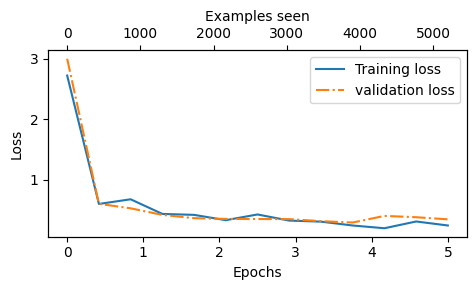

In [ ]:
epochs_tensor =torch.linspace(0, num_epochs, len(train_losses))
examples_seen_tensor =torch.linspace(0, example_seen, len(train_losses))
plot_values(epochs_tensor, examples_seen_tensor, train_losses, val_losses)

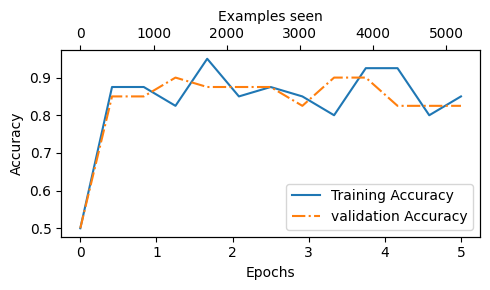

In [ ]:
epochs_tensor =torch.linspace(0, num_epochs, len(train_acc))
examples_seen_tensor =torch.linspace(0, example_seen,len(train_acc))
plot_values(
    epochs_tensor, examples_seen_tensor, train_acc, val_accs, label="Accuracy"
)

In [ ]:
train_accuracy = calc_accuracy_loader(train_loader, model, device)
val_accuracy = calc_accuracy_loader(val_loader, model, device)
test_accuracy = calc_accuracy_loader(test_loader, model, device)

print(f"Training accuracy: {train_accuracy*100:.2f}%")
print(f"Validation accuracy: {val_accuracy*100:.2f}%")
print(f"Test accuracy: {test_accuracy*100:.2f}%")

Training accuracy: 84.90%
Validation accuracy: 86.58%
Test accuracy: 86.33%


In [ ]:
def classify_review(
    text, model,tokenizer, device, max_length =None,
    pad_token_id =50256):
  model.eval()
  input_ids =tokenizer.encode(text)
  supported_context_length =model.pos_emb.weight.shape[1]

  input_ids =input_ids [:min(
      max_length, supported_context_length
  )]

  input_ids +=[pad_token_id] * (max_length - len(input_ids))
  input_tensor =torch.tensor(
      input_ids, device=device
  ).unsqueeze(0)

  with torch.no_grad():
    logits = model(input_tensor)[:, -1,:]
  predicted_label =torch.argmax(logits, dim=-1).item()

  return "spam" if predicted_label == 1 else "not spam"

In [ ]:
text_1 = (
  "You are a winner you have been specially"
  " selected to receive $1000 cash or a $2000 award."
)

In [ ]:
print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


In [ ]:
text_2 = (
"Hey, just wanted to check if we're still on"
" for dinner tonight? Let me know!"
)

In [ ]:
print(classify_review(
    text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


In [ ]:
torch.save(model.state_dict(), "review_classifier.pth")


In [ ]:
model_state_dict =torch.load("review_classifier.pth", map_location=device)
model.load_state_dict(model_state_dict)

<All keys matched successfully>

#Chapter 07

In [ ]:
import json
import os
import urllib

def download_and_load_file(file_path,url):
  if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
      text_data =response.read().decode("utf-8")
    with open(file_path, "w", encoding="utf-8") as file:
      file.write(text_data)
  else:
    with open(file_path, "r", encoding ="utf-8") as file:
      text_data =file.read()
  with open(file_path, "r") as file:
    data =json.load(file)

  return data
file_path ="instruction-data.json"
url =(
    "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch"
    "/main/ch07/01_main-chapter-code/instruction-data.json"
)
data =download_and_load_file(file_path, url)
print("Number of entries:", len(data))


Number of entries: 1100


In [ ]:
print("Example entry:\n", data[50])

Example entry:
 {'instruction': 'Identify the correct spelling of the following word.', 'input': 'Ocassion', 'output': "The correct spelling is 'Occasion.'"}


In [ ]:
print("ANother example entry:\n", data[999])

ANother example entry:
 {'instruction': "What is an antonym of 'complicated'?", 'input': '', 'output': "An antonym of 'complicated' is 'simple'."}


In [ ]:
def format_input(entry):
  instruction_text = (
    f"Below is an instruction that describes a task. "
    f"Write a response that appropriately completes the request."
    f"\n\n### Instruction:\n{entry['instruction']}"
  )
  input_text = (
    f"\n\n### Input:\n{entry['input']}" if entry["input"] else ""
  )
  return instruction_text + input_text

In [ ]:
model_input =format_input(data[50])
desired_response =f"\n\n### Response:\n{data[50]['output']}"
print(model_input +desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Identify the correct spelling of the following word.

### Input:
Ocassion

### Response:
The correct spelling is 'Occasion.'


In [ ]:
model_input =format_input(data[999])
desired_response=f"\n\n### Response:\n{data[999]['output']}"
print(model_input +desired_response)

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What is an antonym of 'complicated'?

### Response:
An antonym of 'complicated' is 'simple'.


In [ ]:
train_portion =int(len(data) * 0.85)
test_portion  =int(len(data) * 0.1)
val_portion   =len(data) - train_portion - test_portion

train_data    =data[:train_portion]
test_data     =data[train_portion: train_portion +test_portion]
val_data      =data[train_portion +test_portion :]

print(f"Training set length:",len(train_data))
print(f"Validation set length:", len(val_data))
print(f"Test set length:", len(test_data))

Training set length: 935
Validation set length: 55
Test set length: 110


In [ ]:
import torch
from torch.utils.data import Dataset

class InstructionDataset(Dataset):
  def __init__(self, data, tokenizer):
    self.data         =data
    self.encoded_texts =[] # Changed from self.encoded_text to self.encoded_texts
    for entry in data:
      instruction_plus_input =format_input(entry)
      response_text          =f"\n\n### Response:\n{entry['output']}"
      full_text              =instruction_plus_input + response_text
      self.encoded_texts.append(
          tokenizer.encode(full_text)
      )
  def __getitem__(self, index):
    return self.encoded_texts[index]

  def __len__(self):
    return len(self.data)

In [ ]:
import tiktoken
tokenizer =tiktoken.get_encoding("gpt2")
print(tokenizer.encode("<|endoftext|>", allowed_special={"<|endoftext|>"}))


[50256]


In [ ]:
def custom_collate_draft_1(batch, pad_token_id=50256, device="cpu"):
  batch_max_length =max(len(item) +1 for item in batch)
  inputs_lst =[]

  for item in batch:
    new_item = item.copy()
    new_item += [pad_token_id]

    padded =(
        new_item + [pad_token_id] *
        (batch_max_length -len(new_item))
    )
    inputs =torch.tensor(padded[:-1])
    inputs_lst.append(inputs)
  inputs_tensor =torch.stack(inputs_lst).to(device)
  return inputs_tensor

In [ ]:
inputs_1 =[0, 1, 2, 3, 4]
inputs_2 =[5, 6]
inputs_3 =[7, 8, 9]
batch =(
    inputs_1,
    inputs_2,
    inputs_3
)
print(custom_collate_draft_1(batch))

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])


In [ ]:
def custom_collate_draft_2(batch, pad_token_id =50256,device="cpu"):
  batch_max_length =max(len(item) +1 for item in batch)
  inputs_lst, targets_lst =[] , []

  for item in batch:
    new_item =item.copy()
    new_item +=[pad_token_id]

    padded =(
        new_item + [pad_token_id] *
        (batch_max_length -len(new_item))
    )
    inputs =torch.tensor(padded[:-1])
    targets=torch.tensor(padded[1:])
    inputs_lst.append(inputs)
    targets_lst.append(targets)

  inputs_tensor =torch.stack(inputs_lst).to(device)
  targets_tensor=torch.stack(targets_lst).to(device)
  return inputs_tensor, targets_tensor



In [ ]:
inputs, targets =custom_collate_draft_2(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256, 50256, 50256, 50256],
        [    8,     9, 50256, 50256, 50256]])


In [ ]:
def custom_collate_fn(batch, pad_token_id=50256, ignore_index=-100, allowed_max_length=None, device="cpu"):
  batch_max_length =max(len(item) + 1 for item in batch)
  inputs_lst, targets_lst =[], []

  for item in batch:
    new_item =item.copy()
    new_item += [pad_token_id]

    padded =(
        new_item +[pad_token_id] *
        (batch_max_length - len(new_item))
    )

    inputs =torch.tensor(padded[:-1])
    targets=torch.tensor(padded[1:])

    mask =targets ==pad_token_id
    indices=torch.nonzero(mask).squeeze()
    if indices.numel() >1:
      targets[indices[1:]] =ignore_index

    if allowed_max_length is not None:
      inputs =inputs[:allowed_max_length]
      targets=targets[:allowed_max_length]

    inputs_lst.append(inputs)
    targets_lst.append(targets)

  inputs_tensor =torch.stack(inputs_lst).to(device)
  targets_tensor=torch.stack(targets_lst).to(device)
  return inputs_tensor, targets_tensor


In [ ]:
inputs, targets =custom_collate_fn(batch)
print(inputs)
print(targets)

tensor([[    0,     1,     2,     3,     4],
        [    5,     6, 50256, 50256, 50256],
        [    7,     8,     9, 50256, 50256]])
tensor([[    1,     2,     3,     4, 50256],
        [    6, 50256,  -100,  -100,  -100],
        [    8,     9, 50256,  -100,  -100]])


In [ ]:
logits_1 =torch.tensor(
    [[-1.0, 1.0],
     [-0.5, 1.5]]
)
targets_1 =torch.tensor([0,1])
loss_1    =torch.nn.functional.cross_entropy(logits_1, targets_1)
print(loss_1)

tensor(1.1269)


In [ ]:
logits_2 = torch.tensor(
  [[-1.0, 1.0],
  [-0.5, 1.5],
  [-0.5, 1.5]]
)
targets_2 =torch.tensor([0,1,1])
loss_2    =torch.nn.functional.cross_entropy(logits_2, targets_2)
print(loss_2)

tensor(0.7936)


In [ ]:
targets_3 =torch.tensor([0, 1, -100])
loss_3    =torch.nn.functional.cross_entropy(logits_2, targets_3)
print(loss_3)

tensor(1.1269)


In [ ]:
device =torch.device("cuda" if torch.cuda.is_available() else "cpu")
# if torch.backends.mps.is_available():
# device =torch.device("mps")
print("Device:",device)

Device: cuda


In [ ]:
from functools import partial

customized_collate_fn =partial(
    custom_collate_fn,
    device =device,
    allowed_max_length =1024
)

In [ ]:
from torch.utils.data import DataLoader

num_workers =0
batch_size  =8

torch.manual_seed(123)

train_dataset =InstructionDataset(train_data, tokenizer)
train_loader  =DataLoader(
    train_dataset,
    batch_size =batch_size,
    collate_fn =customized_collate_fn,
    shuffle   =True,
    drop_last =True,
    num_workers=num_workers
)

val_dataset =InstructionDataset(val_data, tokenizer)
val_loader  =DataLoader(
    val_dataset,
    batch_size =batch_size,
    collate_fn =customized_collate_fn,
    shuffle =False,
    drop_last=False,
    num_workers =num_workers
)

test_dataset =InstructionDataset(test_data, tokenizer)
test_dataset =DataLoader(
    test_dataset,
    batch_size =batch_size,
    collate_fn =customized_collate_fn,
    shuffle =False,
    drop_last =False,
    num_workers=num_workers
)


In [ ]:
print("Train loader:")
for inputs, targets in train_loader:
  print(inputs.shape, targets.shape)

Train loader:
torch.Size([8, 61]) torch.Size([8, 61])
torch.Size([8, 76]) torch.Size([8, 76])
torch.Size([8, 73]) torch.Size([8, 73])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 72]) torch.Size([8, 72])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 75]) torch.Size([8, 75])
torch.Size([8, 62]) torch.Size([8, 62])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 67]) torch.Size([8, 67])
torch.Size([8, 77]) torch.Size([8, 77])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 79]) torch.Size([8, 79])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 66]) torch.Size([8, 66])
torch.Size([8, 83]) torch.Size([8, 83])
torch.Size([8, 68]) torch.Size([8, 68])
torch.Size([8, 80]) torch.Size([8, 80])
torch.Size([8, 71]) torch.Size([8, 71])
torch.Size([8, 69]) torch.Size([8, 69])
torch.Size([8, 65]) torch.Size([8, 65])
torch.Size([8, 68]) torch.

In [ ]:
from gpt_download import download_and_load_gpt2

BASE_CONFIG ={
    "vocab_size": 50257,
    "context_length": 1024,
    "drop_rate": 0.0,
    "qkv_bias": True
}

In [ ]:
model_configs ={
  "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
  "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
  "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
  "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

In [ ]:
CHOOSE_MODEL ="gpt2-medium (355M)"
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

model_size =CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")

settings, params =download_and_load_gpt2(
    model_size =model_size,
    models_dir ="gpt2"
)

File already exists and is up-to-date: gpt2/355M/checkpoint
File already exists and is up-to-date: gpt2/355M/encoder.json
File already exists and is up-to-date: gpt2/355M/hparams.json
File already exists and is up-to-date: gpt2/355M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/355M/model.ckpt.index
File already exists and is up-to-date: gpt2/355M/model.ckpt.meta
File already exists and is up-to-date: gpt2/355M/vocab.bpe


In [ ]:
model =GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval()

GPTModel(
  (tok_emb): Embedding(50257, 1024)
  (pos_emb): Embedding(1024, 1024)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=1024, out_features=1024, bias=True)
        (W_key): Linear(in_features=1024, out_features=1024, bias=True)
        (W_values): Linear(in_features=1024, out_features=1024, bias=True)
        (out_proj): Linear(in_features=1024, out_features=1024, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=1024, out_features=4096, bias=True)
          (1): GELU()
          (2): Linear(in_features=4096, out_features=1024, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_shortcut): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(

In [ ]:
torch.manual_seed(123)
input_text =format_input(val_data[0])
print(input_text)


Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Convert the active sentence to passive: 'The chef cooks the meal every day.'


In [ ]:
token_ids =generate(
    model =model,
    idx =text_to_token_ids(input_text, tokenizer),
    max_new_tokens =35,
    context_size =BASE_CONFIG["context_length"],
    eos_id =50256,
)
generated_text =token_ids_to_text(token_ids, tokenizer)


In [ ]:
response_text =generated_text[len(input_text):].strip()
print(response_text)

"I'm not a fan of the American people's love of the United States of America, but I'm not a fan of the United States of America.


In [ ]:
def calc_loss_batch(input_batch, target_batch, model, device):
  input_batch  =input_batch.to(device)
  target_batch =target_batch.to(device)
  logits  =model(input_batch)
  loss    =torch.nn.functional.cross_entropy(
      logits.flatten(0,1), target_batch.flatten()
  )
  return loss

def calc_loss_loader(data_loader, model, device, num_batches=None):
  total_loss =0.
  if len(data_loader) ==0:
    return float("nan")
  elif num_batches is None:
    num_batches =len(data_loader)
  else:
    num_batches =min(num_batches, len(data_loader))

  for i, (input_batch, target_batch) in enumerate(data_loader):
    if i < num_batches:
      loss =calc_loss_batch(
          input_batch, target_batch, model, device
      )
      total_loss += loss.item()
    else:
      break
  return total_loss / num_batches

model.to(device)
torch.manual_seed(123)

with torch.no_grad():
  train_loss =calc_loss_loader(
      train_loader, model, device, num_batches =5
  )
  val_loss =calc_loss_loader(
      val_loader, model, device, num_batches=5
  )
print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 5.437092685699463
Validation loss: 5.363919258117676


In [ ]:
import time

start_time =time.time()
torch.manual_seed(123)
optimizer =torch.optim.AdamW(
    model.parameters(), lr =0.00005, weight_decay =0.1
)
num_epochs =2

train_losses, val_losses, tokens_seen =train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs =num_epochs, eval_freq=5, eval_iter =5,
    start_context =format_input(val_data[0]), tokenizer=tokenizer
)

end_time =time.time()
execution_time_minutes =(end_time -start_time) /60
print(f"Training completed in {execution_time_minutes:.2f}  minutes")

Ep 1 (step  00000):Train loss 4.451,val loss 4.433
Ep 1 (step  00005):Train loss 1.601,val loss 1.490
Ep 1 (step  00010):Train loss 1.051,val loss 1.138
Ep 1 (step  00015):Train loss 0.982,val loss 1.026
Ep 1 (step  00020):Train loss 0.860,val loss 0.970
Ep 1 (step  00025):Train loss 0.828,val loss 0.926
Ep 1 (step  00030):Train loss 0.854,val loss 0.899
Ep 1 (step  00035):Train loss 0.772,val loss 0.868
Ep 1 (step  00040):Train loss 0.720,val loss 0.850
Ep 1 (step  00045):Train loss 0.669,val loss 0.836
Ep 1 (step  00050):Train loss 0.719,val loss 0.825
Ep 1 (step  00055):Train loss 0.791,val loss 0.812
Ep 1 (step  00060):Train loss 0.751,val loss 0.789
Ep 1 (step  00065):Train loss 0.672,val loss 0.769
Ep 1 (step  00070):Train loss 0.580,val loss 0.760
Ep 1 (step  00075):Train loss 0.592,val loss 0.758
Ep 1 (step  00080):Train loss 0.642,val loss 0.752
Ep 1 (step  00085):Train loss 0.541,val loss 0.738
Ep 1 (step  00090):Train loss 0.592,val loss 0.724
Ep 1 (step  00095):Train loss 0

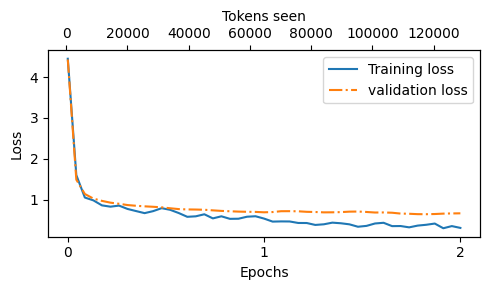

In [ ]:
epochs_tensor =torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

In [ ]:
torch.manual_seed(123)
for entry in test_data[:3]:
  input_text =format_input(entry)
  token_ids =generate(
      model =model,
      idx =text_to_token_ids(input_text, tokenizer).to(device),
      max_new_tokens =256,
      context_size =BASE_CONFIG["context_length"],
      eos_id =50256

  )
  generated_text =token_ids_to_text(token_ids, tokenizer)
  response_text =(
      generated_text[len(input_text):]
      .replace("### Response:", "")
      .strip()
  )
  print(input_text)
  print(f"\nCorrect response:\n>> {entry['output']}")
  print(f"\nModel response:\n>> {response_text.strip()}")
  print("------------------------------------------")

Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Rewrite the sentence using a simile.

### Input:
The car is very fast.

Correct response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.
------------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
What type of cloud is typically associated with thunderstorms?

Correct response:
>> The type of cloud typically associated with thunderstorms is cumulonimbus.

Model response:
>> A thunderstorm is typically associated with a strong wind.
------------------------------------------
Below is an instruction that describes a task. Write a response that appropriately completes the request.

### Instruction:
Name the author of 'Pride and Prejudice'.

Correct response:
>> Jane Austen.

Model response:
>> The author of 'Pride and Pre

In [ ]:
from tqdm import tqdm

for i, entry in tqdm (enumerate(test_data), total=len(test_data)):
  input_text =format_input(entry)

  token_ids =generate(
      model=model,
      idx  =text_to_token_ids(input_text, tokenizer).to(device),
      max_new_tokens =256,
      context_size =BASE_CONFIG["context_length"],
      eos_id =50256,
  )
  generated_text =token_ids_to_text(token_ids, tokenizer)
  response_text =(
      generated_text[len(input_text):]
      .replace("### Response:","")
      .strip()
  )
  test_data[i]["model_response"] =response_text
with open("instruction-data-with-response.json", "w") as file:
  json.dump(test_data, file, indent=4)


100%|██████████| 110/110 [01:11<00:00,  1.55it/s]


In [ ]:
print(text_data[0])

In [ ]:
import re

file_name =f"{re.sub(r'[ ()]', '', CHOOSE_MODEL)}-sft.pth"
torch.save(model.state_dict(), file_name)
print(f"Model saved as {file_name}")


Model saved as gpt2-medium355M-sft.pth


In [ ]:
!ollama run llama3

/bin/bash: line 1: ollama: command not found


In [ ]:
!sudo apt-get update && sudo apt-get install zstd -y
!curl -fsSL https://ollama.com/install.sh | sh

Get:1 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease [3,632 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  InRelease [1,581 B]
Get:3 https://cli.github.com/packages stable InRelease [3,917 B]
Get:4 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2204/x86_64  Packages [2,797 kB]
Get:5 http://security.ubuntu.com/ubuntu jammy-security InRelease [129 kB]
Get:6 https://r2u.stat.illinois.edu/ubuntu jammy InRelease [6,555 B]
Get:7 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ Packages [99.9 kB]
Get:8 https://cli.github.com/packages stable/main amd64 Packages [354 B]
Get:9 https://r2u.stat.illinois.edu/ubuntu jammy/main amd64 Packages [3,085 kB]
Get:10 http://security.ubuntu.com/ubuntu jammy-security/universe amd64 Packages [1,308 kB]
Get:11 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease [18.1 kB]
Hit:12 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:13 https://ppa.launchpadcon

In [ ]:
import psutil

def check_if_running(process_name):
  running = False
  for proc in psutil.process_iter(['name']):
    if process_name in proc.info["name"]:
      running = True
      break
  return running

ollama_running = check_if_running("ollama")

if not ollama_running:
  raise RuntimeError(
      "Ollama not running. Launch ollama before proceding."
  )
print("Ollama runnign:", check_if_running("ollama"))

RuntimeError: Ollama not running. Launch ollama before proceding.

In [ ]:
import time

!ollama serve &
time.sleep(5) # Give Ollama some time to start up

time=2026-06-30T18:36:22.121Z level=INFO source=routes.go:1961 msg="server config" env="map[CUDA_VISIBLE_DEVICES: GGML_VK_VISIBLE_DEVICES: GPU_DEVICE_ORDINAL: HIP_VISIBLE_DEVICES: HSA_OVERRIDE_GFX_VERSION: HTTPS_PROXY: HTTP_PROXY: LLAMA_ARG_FIT: LLAMA_ARG_FIT_TARGET: NO_PROXY: OLLAMA_CONTEXT_LENGTH:0 OLLAMA_DEBUG:INFO OLLAMA_DEBUG_LOG_REQUESTS:false OLLAMA_EDITOR: OLLAMA_FLASH_ATTENTION:false OLLAMA_GO_TEMPLATE:true OLLAMA_GPU_OVERHEAD:0 OLLAMA_HOST:http://127.0.0.1:11434 OLLAMA_IGPU_ENABLE: OLLAMA_KEEP_ALIVE:5m0s OLLAMA_KV_CACHE_TYPE: OLLAMA_LLM_LIBRARY: OLLAMA_LOAD_TIMEOUT:5m0s OLLAMA_MAX_LOADED_MODELS:0 OLLAMA_MAX_QUEUE:512 OLLAMA_MAX_TRANSFER_STREAMS:4 OLLAMA_MODELS:/root/.ollama/models OLLAMA_NOHISTORY:false OLLAMA_NOPRUNE:false OLLAMA_NO_CLOUD:false OLLAMA_NUM_PARALLEL:1 OLLAMA_ORIGINS:[http://localhost https://localhost http://localhost:* https://localhost:* http://127.0.0.1 https://127.0.0.1 http://127.0.0.1:* https://127.0.0.1:* http://0.0.0.0 https://0.0.0.0 http://0.0.0.0:* 

KeyboardInterrupt: 

In [ ]:
import urllib.request

def query_model(
    prompt,
    model="llama3",
    url="http://localhost:11434/api/chat" ):

  data={
      "model": model,
      "messages": [
          {"role": "user", "content": prompt}
      ],
      "options": {
          "seed":123,
          "temperature":0,
          "num_ctx": 2048
      }
  }

  payload =json.dumps(data).encode('utf-8')
  request = urllib.request.Request(
            url,
            data=payload,
            method="POST"
            )
  request.add_header("Content-Type", "application/json")
  response_data = ""
  with urllib.request.urlopen(request) as response:
    while True:
      line =response.readline().decode("utf-8")
      if not line:
        break
      response_json =json.loads(line)
      response_data +=response_json['message']["content"]
  return response_data

In [ ]:
model ="llama3"
result =query_model("What do Llamas eat?", model)
print(result)

URLError: <urlopen error [Errno 111] Connection refused>

In [ ]:
for entry in test_data[:3]:
  prompt =(
      f"Given the input '{format_input(entry)}'"
      f"and correct output `{entry['output']}`, "
      f"score the model response `{entry['model_response']}`"
      f" on a scale from 0 to 100, where 100 is the best score. "
  )

  print("\nDataset response:")
  print(">>", entry['output'])
  print("\nModel response:")
  print(">>", entry["model_response"])
  print("\nScore:")
  print(">>", query_model(prompt))
  print("\n-------------------------")



Dataset response:
>> The car is as fast as lightning.

Model response:
>> The car is as fast as a bullet.

Score:


URLError: <urlopen error [Errno 111] Connection refused>

In [ ]:
def generate_model_scores(json_data, json_key, model="llama3"):
    scores = []
    for entry in tqdm(json_data, desc="Scoring entries"):
        prompt = (
        f"Given the input `{format_input(entry)}` "
        f"and correct output `{entry['output']}`, "
        f"score the model response `{entry[json_key]}`"
        f" on a scale from 0 to 100, where 100 is the best score. "
        f"Respond with the integer number only."
        )
        score = query_model(prompt, model)

        try:
          scores.append(int(score))
        except ValueError:
          print(f"Could not convert score: {score}")
        continue
    return scores

In [ ]:
scores = generate_model_scores(test_data, "model_response")
print(f"Number of scores: {len(scores)} of {len(test_data)}")
print(f"Average score: {sum(scores)/len(scores):.2f}\n")

Scoring entries:   0%|          | 0/110 [00:00<?, ?it/s]


URLError: <urlopen error [Errno 111] Connection refused>

#Appendix A

#Appendix C

#Appendix D